<a href="https://colab.research.google.com/github/Maruf0275/Machine-Learning-CIT/blob/main/Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [36]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [19]:
df = pd.read_csv('/content/drive/MyDrive/Machine Learning(CIT)/Datasets/id3.csv')

In [20]:
df.head()

,Outlook,Temperature,Humidity,Wind,Answer
0,sunny,hot,high,weak,no
1,sunny,hot,high,strong,no
2,overcast,hot,high,weak,yes
3,rain,mild,high,weak,yes
4,rain,cool,normal,weak,yes


In [21]:
df.shape

(14, 5)

In [22]:
le = LabelEncoder()

In [23]:
for col in df.columns:
    df[col] = le.fit_transform(df[col])

In [24]:
df.head()

,Outlook,Temperature,Humidity,Wind,Answer
0,2,1,0,1,0
1,2,1,0,0,0
2,0,1,0,1,1
3,1,2,0,1,1
4,1,0,1,1,1


In [25]:
x = df['Answer']
y = df.drop(columns=['Answer'])

print("Shape of target (x):", x.shape)
print("Shape of features (y):", y.shape)

Shape of target (x): (14,)
Shape of features (y): (14, 4)


In [26]:
x = df.drop(columns=['Answer'])
y = df['Answer']

In [27]:
y.head()

,Answer
0,0
1,0
2,1
3,1
4,1


In [28]:
x.head()

,Outlook,Temperature,Humidity,Wind
0,2,1,0,1
1,2,1,0,0
2,0,1,0,1
3,1,2,0,1
4,1,0,1,1


In [29]:
dt = DecisionTreeClassifier()

In [30]:
dt = DecisionTreeClassifier(criterion='entropy')

In [31]:
model = dt.fit(x, y)

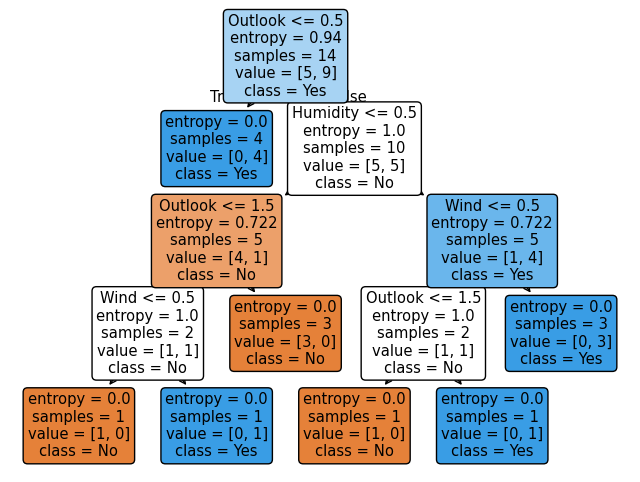

In [32]:
plt.figure(figsize=(8, 6))
tree.plot_tree(model, feature_names=list(x.columns), class_names=['No', 'Yes'], filled=True, rounded=True)
plt.show()

In [33]:
model.score(x,y)

1.0

In [34]:
model.predict([[1,2,0,1]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [37]:
# Generate predictions for the training set
y_pred = model.predict(x)

# Calculate metrics
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred)
recall = recall_score(y, y_pred)
f1 = f1_score(y, y_pred)

# Display the results
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y, y_pred, target_names=['No', 'Yes']))

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         5
         Yes       1.00      1.00      1.00         9

    accuracy                           1.00        14
   macro avg       1.00      1.00      1.00        14
weighted avg       1.00      1.00      1.00        14



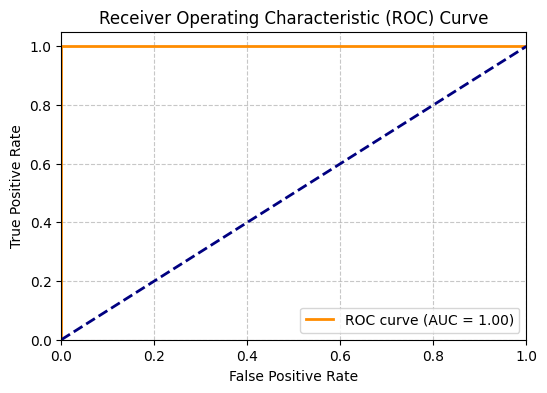

In [40]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Get decision tree probabilities for the positive class
y_probs = model.predict_proba(x)[:, 1]

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y, y_probs)
roc_auc = auc(fpr, tpr)

# Plot the ROC Curve
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()